# Do ensembles of trees get worse when we add more trees

[Master Tree Ensemble Models course](https://www.trainindata.com/p/master-tree-ensemble-models)

We train a random forest, an AdaBoost and a gradient boosting machine with two thousand trees each, and we follow the performance in the test set after every tree that we add.

We do this first with artificial data, and then with five real datasets, and at the end we compare the performance in the train set with the performance in the test set, to see which of the three models overfits.

In [10]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml, make_classification
from sklearn.ensemble import (
    AdaBoostClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

N_ESTIMATORS = 2000
MODELS = ["random forest", "adaboost", "gradient boosting"]

### The experiment

The two boosting models give us the performance after each tree with `staged_predict_proba`.

The random forest does not, because its trees are independent and the order in which we add them is arbitrary, so we ask every tree for its prediction and we average the first tree, then the first two, then the first three, and so on, which is the forest that we would have obtained with that many trees.

In [11]:
def prepare(X, y):
    X = pd.DataFrame(X).copy()
    for var in X.columns:
        if str(X[var].dtype) in ("object", "category", "str"):
            X[var] = X[var].astype("category").cat.codes
    X = X.astype(float).fillna(-1)
    y = pd.Series(np.asarray(y)).astype("category").cat.codes
    return X, y


def make_model(name):
    if name == "random forest":
        return RandomForestClassifier(n_estimators=N_ESTIMATORS, random_state=0, n_jobs=-1)
    if name == "adaboost":
        return AdaBoostClassifier(n_estimators=N_ESTIMATORS, random_state=0)
    return GradientBoostingClassifier(n_estimators=N_ESTIMATORS, random_state=0)

In [12]:
def predictions_after_each_tree(model, X):
    if isinstance(model, RandomForestClassifier):
        trees = np.array([tree.predict_proba(X.to_numpy())[:, 1] for tree in model.estimators_])
        return np.cumsum(trees, axis=0) / np.arange(1, len(trees) + 1)[:, None]
    return [p[:, 1] for p in model.staged_predict_proba(X)]


def roc_auc_curves(name, X, y):
    X, y = prepare(X, y)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, stratify=y, random_state=0
    )
    model = make_model(name)
    model.fit(X_train, y_train)

    curves = {}
    for set_name, features, target in [("train", X_train, y_train), ("test", X_test, y_test)]:
        curves[set_name] = [
            roc_auc_score(target, p) for p in predictions_after_each_tree(model, features)
        ]
    return pd.DataFrame(curves, index=range(1, len(curves["test"]) + 1))

### Artificial Data

We make one dataset and we use it three times, once with clean labels, and twice with the labels of ten and twenty percent of the observations flipped, because the weakness that everybody mentions about boosting is that it chases the observations that it predicts badly, and a wrong label is an observation that no model can ever predict well.

In [13]:
X, y = make_classification(n_samples=6000, n_features=20, n_informative=6, random_state=0)

targets = {"clean labels": y}
for noise in [0.1, 0.2]:
    rng = np.random.default_rng(0)
    targets[f"{int(noise * 100)}% wrong labels"] = np.where(rng.random(len(y)) < noise, 1 - y, y)

toy = {
    (name, labels): roc_auc_curves(name, X, target)
    for name in MODELS
    for labels, target in targets.items()
}

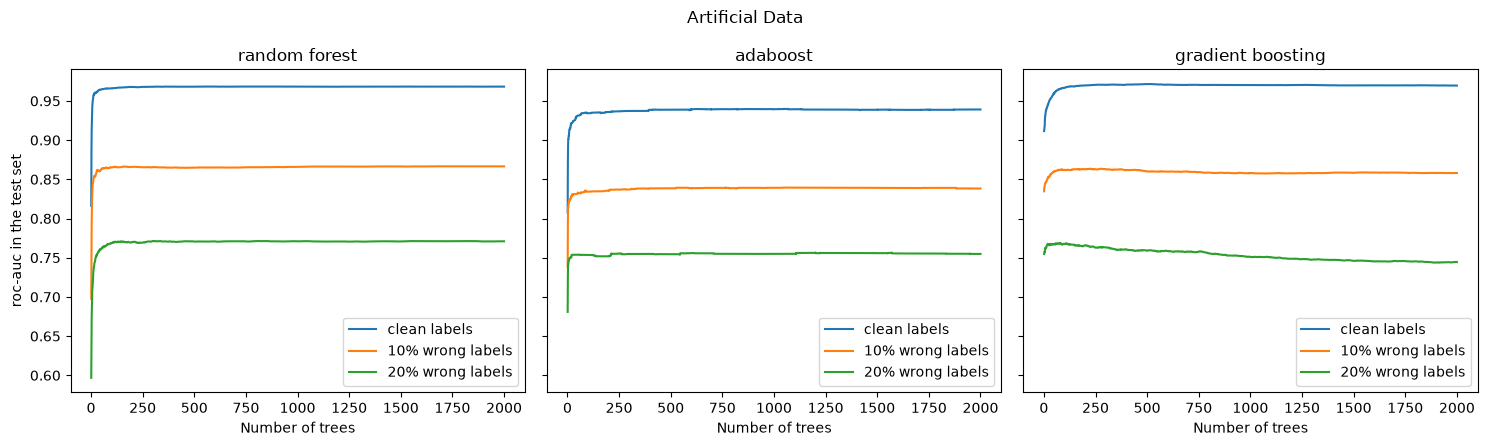

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, name in zip(axes, MODELS):
    for labels in targets:
        curve = toy[(name, labels)]["test"]
        ax.plot(curve.index, curve, label=labels)
    ax.set_xlabel("Number of trees")
    ax.set_title(name)
    ax.legend(loc="lower right")
axes[0].set_ylabel("roc-auc in the test set")
fig.suptitle("Artificial Data")
fig.tight_layout()
plt.show()

### Real datasets

In [6]:
datasets = {
    "credit-g": 31,
    "diabetes": 37,
    "spambase": 44,
    "phoneme": 1489,
    "churn": 40701,
}

data = {name: fetch_openml(data_id=data_id, as_frame=True) for name, data_id in datasets.items()}

real = {
    (name, dataset): roc_auc_curves(name, data[dataset].data, data[dataset].target)
    for name in MODELS
    for dataset in datasets
}

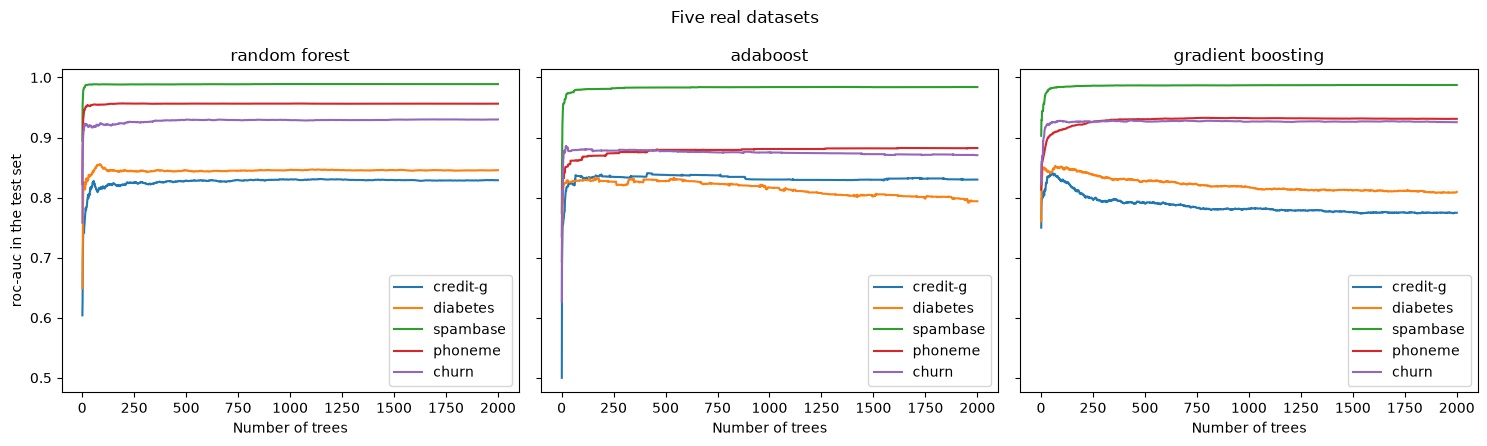

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, name in zip(axes, MODELS):
    for dataset in datasets:
        curve = real[(name, dataset)]["test"]
        ax.plot(curve.index, curve, label=dataset)
    ax.set_xlabel("Number of trees")
    ax.set_title(name)
    ax.legend(loc="lower right")
axes[0].set_ylabel("roc-auc in the test set")
fig.suptitle("Real datasets")
fig.tight_layout()
plt.show()

- Adding more trees to random forests does not seem to deteriorate the performance of the ensemble.

- Adding more trees to AdaBoost deteriorated the performance of the ensemble in 2 of the 5 datasets: churn and diabetes.

- Adding more trees to gradient boosting deteriorated the performance of the ensemble in 2 of the 5 datasets: credit and diabetes, to a worse degree than adaboost.

In terms of sensitivity to the number of trees:

- gradient boosting > adaboost > random forest 

In [8]:
summary = {
    (name, dataset): {
        "best test": curve["test"].max(),
        "best at tree": curve["test"].idxmax(),
        "final test": curve["test"].iloc[-1],
        "lost from best %": 100
        * (curve["test"].max() - curve["test"].iloc[-1])
        / curve["test"].max(),
        "final train": curve["train"].iloc[-1],
    }
    for (name, dataset), curve in real.items()
}

summary = pd.DataFrame(summary).T
summary.index.names = ["model", "dataset"]
summary.round(4)

best test  best at tree  final test  \
model             dataset                                         
random forest     credit-g     0.8311        1143.0      0.8289   
                  diabetes     0.8556          85.0      0.8457   
                  spambase     0.9891        1061.0      0.9890   
                  phoneme      0.9569         196.0      0.9564   
                  churn        0.9302        1681.0      0.9302   
adaboost          credit-g     0.8408         415.0      0.8301   
                  diabetes     0.8336         163.0      0.7940   
                  spambase     0.9843        1162.0      0.9841   
                  phoneme      0.8827        1622.0      0.8826   
                  churn        0.8862          21.0      0.8707   
gradient boosting credit-g     0.8407          56.0      0.7748   
                  diabetes     0.8526          68.0      0.8095   
                  spambase     0.9876        1721.0      0.9875   
                  phoneme      0.9330         782.0      0.9312   
                  churn        0.9287         425.0      0.9256   

                            lost from best %  final train  
model             dataset                                  
random forest     credit-g            0.2642       1.0000  
                  diabetes            1.1544       1.0000  
                  spambase            0.0151       1.0000  
                  phoneme             0.0526       1.0000  
                  churn               0.0067       1.0000  
adaboost          credit-g            1.2837       0.8603  
                  diabetes            4.7539       0.9656  
                  spambase            0.0241       0.9955  
                  phoneme             0.0160       0.9166  
                  churn               1.7454       0.9287  
gradient boosting credit-g            7.8419       1.0000  
                  diabetes            5.0584       1.0000  
                  spambase            0.0087       1.0000  
                  phoneme             0.1912       1.0000  
                  churn               0.3332       1.0000

### Do the models overfit

Now we plot the performance in the train set next to the performance in the test set, one row per model and one column per dataset.

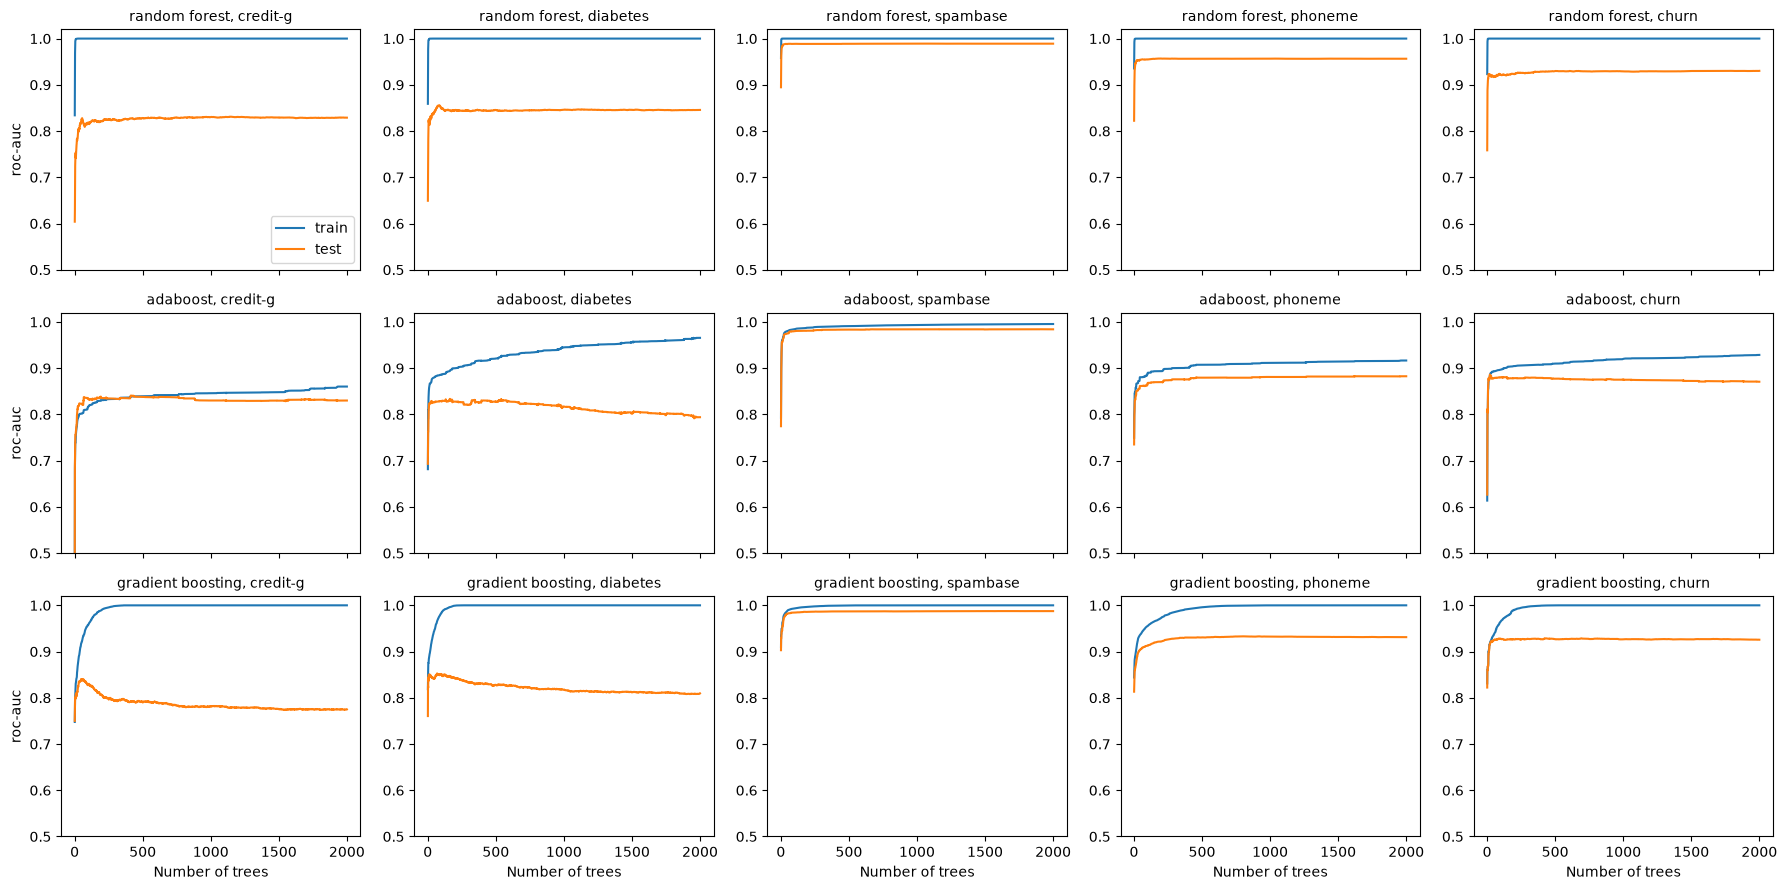

In [9]:
fig, axes = plt.subplots(len(MODELS), len(datasets), figsize=(18, 9), sharex=True)
for row, name in zip(axes, MODELS):
    for ax, dataset in zip(row, datasets):
        curve = real[(name, dataset)]
        ax.plot(curve.index, curve["train"], label="train")
        ax.plot(curve.index, curve["test"], label="test")
        ax.set_ylim(0.5, 1.02)
        ax.set_title(f"{name}, {dataset}", fontsize=10)
for ax in axes[-1]:
    ax.set_xlabel("Number of trees")
for row in axes:
    row[0].set_ylabel("roc-auc")
axes[0][0].legend(loc="lower right")
fig.tight_layout()
plt.show()

Random forests and gradient boosting machines are quick to overfit to the data: they overfit in all 5 datasets. AdaBoost also captures noise, but it is more resilient, with smaller preformance differences between train and test in all 5 datasets and not overfitting in the credit g dataset.